In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")

In [4]:
X=pd.concat([train,test],axis=0,ignore_index=True)

In [5]:
X=X.drop('SalePrice',axis=1)

In [6]:
print(X.info())

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             2919 non-null   int64  
 1   MSSubClass     2919 non-null   int64  
 2   MSZoning       2915 non-null   str    
 3   LotFrontage    2433 non-null   float64
 4   LotArea        2919 non-null   int64  
 5   Street         2919 non-null   str    
 6   Alley          198 non-null    str    
 7   LotShape       2919 non-null   str    
 8   LandContour    2919 non-null   str    
 9   Utilities      2917 non-null   str    
 10  LotConfig      2919 non-null   str    
 11  LandSlope      2919 non-null   str    
 12  Neighborhood   2919 non-null   str    
 13  Condition1     2919 non-null   str    
 14  Condition2     2919 non-null   str    
 15  BldgType       2919 non-null   str    
 16  HouseStyle     2919 non-null   str    
 17  OverallQual    2919 non-null   int64  
 18  OverallCond    2919

### 缺失值补充

由于这里面许多类别特征，有一些类别太稀有就合并了  
有些特征没法推测出来，直接把缺失值当成另一个类，太过稀少直接合并

In [7]:
X['MSZoning'].value_counts()

MSZoning
RL         2265
RM          460
FV          139
RH           26
C (all)      25
Name: count, dtype: int64

In [8]:
X['MSZoning']=X['MSZoning'].fillna('Missing')

In [9]:
X['MSZoning'] = X['MSZoning'].replace(['FV', 'RH', 'C (all)', 'Missing'], 'rear')

这几个特征类别极度不平衡

In [10]:
dic=['Alley','PoolQC','MiscFeature']
for item in dic:
   X[item]=X[item].fillna('Missing')
   X[item]=np.where(X[item]=='Missing',0,1)
   print(X[item].value_counts())

Alley
0    2721
1     198
Name: count, dtype: int64
PoolQC
0    2909
1      10
Name: count, dtype: int64
MiscFeature
0    2814
1     105
Name: count, dtype: int64


这个没有价值，直接丢掉

In [11]:
# X['Utilities'].value_counts()
# Utilities
# AllPub    2916
# NoSeWa       1
X=X.drop('Utilities',axis=1)

In [12]:
# X['Exterior1st'].value_counts()
# Exterior1st
# VinylSd    1025
# MetalSd     450
# HdBoard     442
# Wd Sdng     411
# Plywood     221
# CemntBd     126
# BrkFace      87
# WdShing      56
# AsbShng      44
# Stucco       43
# BrkComm       6
# AsphShn       2
# Stone         2
# CBlock        2
# ImStucc       1
X['Exterior1st']=X['Exterior1st'].fillna('Missing')
X['Exterior1st'] = X['Exterior1st'].replace(['BrkFace','WdShing','AsbShng','Stucco','BrkComm',
         'AsphShn','Stone','CBlock','ImStucc','Missing'], 'rear')
X['Exterior1st'].value_counts()

Exterior1st
VinylSd    1025
MetalSd     450
HdBoard     442
Wd Sdng     411
rear        244
Plywood     221
CemntBd     126
Name: count, dtype: int64

In [13]:
# Exterior2nd
# VinylSd    1014
# MetalSd     447
# HdBoard     406
# Wd Sdng     391
# Plywood     270
# CmentBd     126
# Wd Shng      81
# BrkFace      47
# Stucco       47
# AsbShng      38
# Brk Cmn      22
# ImStucc      15
# Stone         6
# AsphShn       4
# CBlock        3
# Other         1
X['Exterior2nd']=X['Exterior2nd'].fillna('Missing')
X['Exterior2nd'] = X['Exterior2nd'].replace(['Wd Shng','BrkFace',
    'Stucco','AsbShng','Brk Cmn','ImStucc','Stone','AsphShn','CBlock','Other','Missing'], 'rear')
X['Exterior2nd'].value_counts()

Exterior2nd
VinylSd    1014
MetalSd     447
HdBoard     406
Wd Sdng     391
Plywood     270
rear        265
CmentBd     126
Name: count, dtype: int64

有些特征之间是有联系得，都是描述的同一个房屋特征，需要结合这一类其他特征来填充缺失值

In [14]:
# 显示所有行
pd.set_option('display.max_rows', None)
# 显示所有列
pd.set_option('display.max_columns', None)
missing_masvnrtype=X[X['MasVnrType'].isnull()]
display(missing_masvnrtype[['MasVnrType','MasVnrArea']].T)

,1,3,5,8,9,10,12,15,17,18,19,21,23,24,26,28,29,30,31,32,33,36,38,39,41,42,43,44,46,47,48,49,50,51,52,53,54,57,59,60,61,63,68,69,71,74,75,76,77,78,79,86,88,89,90,92,93,94,98,99,102,103,106,107,108,110,111,114,117,118,119,120,121,123,124,125,126,127,132,134,139,140,141,142,146,149,150,153,154,155,156,158,160,163,164,165,166,168,170,172,175,177,179,181,183,184,185,186,187,189,190,192,194,195,197,198,200,201,202,204,205,206,207,210,211,212,213,217,220,221,222,223,228,233,234,237,239,241,242,243,244,246,247,250,252,254,256,259,263,264,266,267,268,270,271,274,275,276,277,284,285,286,287,289,290,291,292,295,296,299,301,303,304,307,308,309,311,312,313,314,315,317,323,325,326,328,329,331,334,335,338,340,341,344,345,346,351,352,353,354,355,357,360,361,365,369,370,371,372,373,374,375,376,377,380,381,382,383,384,386,390,391,392,393,394,395,396,398,400,401,402,404,405,406,407,410,411,413,414,415,417,418,419,422,425,427,429,431,433,434,435,436,437,438,439,442,444,445,446,447,448,449,450,451,453,454,456,457,458,461,462,463,466,470,471,474,475,482,484,485,487,488,489,490,491,492,493,494,495,496,497,499,501,502,503,504,507,508,512,513,514,518,519,520,521,522,525,526,528,529,531,532,533,534,535,536,537,542,544,546,547,548,549,550,551,553,555,556,557,558,561,562,563,564,565,568,569,572,573,575,576,578,583,584,586,587,588,589,590,592,594,596,599,601,602,603,606,607,608,613,614,616,617,620,621,624,626,630,633,634,635,636,637,638,639,641,642,645,646,649,650,651,652,653,657,658,659,663,664,668,669,670,671,672,674,675,676,677,680,681,682,685,686,687,693,694,696,697,698,699,703,705,708,710,711,712,716,717,719,720,722,723,725,729,730,733,734,735,736,737,738,739,740,741,743,744,746,747,749,750,751,752,754,756,760,761,762,764,767,768,770,771,772,773,777,781,782,784,785,786,787,788,791,792,794,797,800,801,802,804,806,807,809,812,814,816,820,821,822,823,824,826,827,828,829,831,835,836,838,839,840,841,843,844,845,847,848,852,854,855,856,857,860,861,862,863,864,867,868,870,872,873,874,875,876,878,880,882,883,887,888,890,892,893,894,896,897,899,900,901,902,907,908,909,911,912,913,916,917,918,919,921,922,923,925,928,930,931,934,936,937,938,939,940,942,943,945,949,950,951,952,956,957,958,959,960,962,963,965,966,968,970,972,973,974,975,976,977,978,979,983,984,985,986,989,991,993,995,996,998,1000,1001,1006,1007,1009,1010,1011,1012,1013,1015,1017,1020,1022,1024,1025,1028,1030,1031,1032,1034,1035,1038,1039,1044,1045,1047,1049,1050,1051,1057,1060,1061,1062,1063,1065,1066,1068,1069,1071,1072,1074,1075,1076,1077,1079,1081,1084,1085,1086,1087,1089,1090,1092,1094,1095,1096,1097,1098,1100,1101,1103,1106,1107,1108,1110,1112,1113,1114,1116,1117,1118,1119,1120,1122,1123,1125,1127,1128,1130,1131,1132,1133,1134,1135,1136,1137,1138,1139,1140,1143,1144,1145,1147,1148,1149,1150,1152,1153,1155,1156,1160,1162,1163,1164,1167,1168,1170,1171,1172,1173,1174,1176,1177,1178,1179,1180,1182,1183,1185,1186,1187,1189,1192,1195,1196,1197,1198,1200,1201,1202,1204,1206,1208,1210,1211,1212,1213,1214,1215,1216,1218,1220,1221,1224,1229,1230,1232,1234,1235,1237,1238,1243,1244,1246,1248,1249,1250,1252,1253,1255,1257,1259,1260,1261,1262,1263,1264,1266,1267,1270,1271,1274,1276,1278,1279,1282,1283,1284,1285,1288,1292,1293,1294,1299,1300,1301,1307,1308,1310,1314,1315,1317,1320,1321,1322,1323,1325,1326,1327,1328,1329,1331,1332,1333,1334,1337,1338,1339,1340,1341,1343,1344,1345,1346,1348,1349,1352,1354,1357,1360,1362,1363,1364,1365,1367,1370,1371,1372,1374,1376,1377,1379,1380,1381,1382,1383,1384,1385,1387,1389,1391,1392,1393,1396,1397,1398,1399,1400,1401,1402,1404,1406,1407,1408,1410,1411,1412,1414,1416,1418,1421,1423,1424,1427,1430,1431,1432,1434,1436,1438,1440,1443,1445,1448,1449,1450,1453,1454,1455,1457,1458,1459,1460,1462,1464,1465,1466,1467,1468,1469,1470,1473,1474,1482,1484,1485,1488,1489,1491,1495,1496,1498,1501,1502,1503,1504,1506,1507,1508,1510,1512,1517,1522,1523,1524,1525,1526,1527,1528,1531,1532,1533,1534,1535,1536,1537,1538,1539,1540,1541,1542,1543,1544,1545,1547,1548,1549,1550,1551,1552,1553

In [15]:
# 筛选：MasVnrType 为空，并且 MasVnrArea 为 0
condition = (X['MasVnrType'].isnull()) & (X['MasVnrArea'] == 0)
# 将这些行的 MasVnrType 填充为 'Missing' (注意大小写，通常推荐首字母大写)
X.loc[condition, 'MasVnrType'] = 'Missing'

condition2=(X['MasVnrType'].isnull())&(X['MasVnrArea'].isnull())
X.loc[condition2,'MasVnrType']='Missing'
X.loc[condition2,'MasVnrArea']=0

In [16]:
# condition=(X['MasVnrArea']>0) & (X['MasVnrArea']<15)
# col=X[condition]
# display(col['MasVnrType'])
# 773         NaN
# 790     BrkFace
# 1023    BrkFace
# 1230        NaN
# 1483    BrkFace
# 1765    BrkFace
# 2452        NaN
# 2671    BrkFace
# 2674    BrkFace
condition3=(X['MasVnrArea']==1)
X.loc[condition3,'MasVnrType']='BrkFace'

In [17]:
# condition=(X['MasVnrArea']>190) & (X['MasVnrArea']<200)
# col=X[condition]
# display(col['MasVnrType'])
X.loc[2610, 'MasVnrType'] = 'BrkFace'

In [18]:
# condition=(X['MasVnrArea']>280) & (X['MasVnrArea']<350)
# col=X[condition]
# display(col['MasVnrType'])
X['MasVnrType']=X['MasVnrType'].fillna('BrkFace')

In [19]:
missing_Bsmt=X[X['BsmtExposure'].isnull()]
cols = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
        'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF']

display(missing_Bsmt[cols].T)

,17,39,90,102,156,182,259,342,362,371,392,520,532,533,553,646,705,736,749,778,868,894,897,948,984,1000,1011,1035,1045,1048,1049,1090,1179,1216,1218,1232,1321,1412,1487,1585,1593,1729,1778,1814,1847,1848,1856,1857,1858,1860,1915,2050,2066,2068,2120,2122,2188,2189,2190,2193,2216,2224,2348,2387,2435,2452,2453,2490,2498,2547,2552,2564,2578,2599,2702,2763,2766,2803,2804,2824,2891,2904
BsmtQual,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Gd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Gd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Gd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BsmtCond,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BsmtExposure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BsmtFinType1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BsmtFinSF1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BsmtFinType2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BsmtFinSF2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BsmtUnfSF,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,936.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1595.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,725.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TotalBsmtSF,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,936.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1595.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,725.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
condition=(X['TotalBsmtSF']==0)
cols = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
          'BsmtFinType2']
X.loc[condition,cols]='Missing'

In [21]:
X.loc[2120,['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
          'BsmtFinType2']]='Missing'
X.loc[2120,['BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF']]=0

In [22]:
# BsmtExposure
# No    655
# Av    247
# Gd    125
# Mn    103
# condition=(X['BsmtQual']=='Gd')&(X['BsmtCond']=='TA')
# cols=X[condition]
# display(cols['BsmtExposure'].value_counts())
X['BsmtExposure']=X['BsmtExposure'].fillna('No')

In [23]:
X['Electrical']=X['Electrical'].fillna(X['Electrical'].mode()[0])

In [24]:
missing_bsmtbath=X[X['BsmtFullBath'].isnull()]
cols = ['BsmtFullBath', 'BsmtHalfBath', 'TotalBsmtSF']
display(missing_bsmtbath[cols])

,BsmtFullBath,BsmtHalfBath,TotalBsmtSF
2120,NaN,NaN,0.0
2188,NaN,NaN,0.0


In [25]:
X['BsmtFullBath'] = X['BsmtFullBath'].fillna(0)
X['BsmtHalfBath'] = X['BsmtHalfBath'].fillna(0)

In [26]:
X['KitchenQual'] = X['KitchenQual'].fillna(X['KitchenQual'].mode()[0])

In [27]:
X['Functional'] = X['Functional'].fillna(X['Functional'].mode()[0])

In [28]:
# 选出 FireplaceQu 为空的样本，只看 Fireplaces 和 FireplaceQu 这两列
X.loc[X['FireplaceQu'].isnull(), ['Fireplaces', 'FireplaceQu']]

,Fireplaces,FireplaceQu
0,0,NaN
5,0,NaN
10,0,NaN
12,0,NaN
15,0,NaN
17,0,NaN
18,0,NaN
19,0,NaN
26,0,NaN
29,0,NaN


In [29]:
condition=(X['Fireplaces']==0)&(X['FireplaceQu'].isnull())
X.loc[condition,'FireplaceQu']='Missing'

In [30]:
missing_garagearea=X[X['GarageCond'].isnull()]
garage_cols = ['GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond']
display(missing_garagearea[garage_cols].T)

,39,48,78,88,89,99,108,125,127,140,148,155,163,165,198,210,241,250,287,291,307,375,386,393,431,434,441,464,495,520,528,533,535,562,582,613,614,620,635,636,638,649,705,710,738,750,784,826,843,921,942,954,960,968,970,976,1009,1011,1030,1038,1096,1123,1131,1137,1143,1173,1179,1218,1219,1234,1257,1283,1323,1325,1326,1337,1349,1407,1449,1450,1453,1513,1531,1539,1552,1556,1558,1560,1590,1593,1594,1614,1615,1717,1721,1787,1808,1810,1811,1819,1822,1831,1834,1836,1839,1847,1893,2010,2081,2090,2093,2096,2099,2104,2126,2135,2151,2153,2189,2190,2191,2192,2193,2212,2238,2246,2353,2354,2398,2399,2422,2426,2552,2553,2557,2575,2576,2579,2603,2609,2691,2693,2708,2767,2771,2789,2791,2799,2859,2862,2870,2888,2891,2892,2893,2909,2913,2914,2917
GarageType,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Detchd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Detchd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GarageYrBlt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GarageFinish,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GarageCars,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
GarageArea,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,360.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
GarageQual,NaN,NaN,N

In [31]:
str_cols = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
float_cols = ['GarageYrBlt', 'GarageCars', 'GarageArea']
X.loc[X['GarageArea']==0,str_cols]='Missing'
X.loc[X['GarageArea']==0,float_cols]=0

In [32]:
# 1. 提取 Detchd 类型的子集，算出所需的众数和均值
detchd_df = X[X['GarageType'] == 'Detchd']
mode_finish = detchd_df['GarageFinish'].mode()[0]
mode_qual = detchd_df['GarageQual'].mode()[0]
mode_cond = detchd_df['GarageCond'].mode()[0]
mean_cars = detchd_df['GarageCars'].mean()
mean_area = detchd_df['GarageArea'].mean()

# 2. 两个样本的 GarageYrBlt 改为对应的 YearBuilt
X.loc[[2126, 2576], 'GarageYrBlt'] = X.loc[[2126, 2576], 'YearBuilt']

# 3. 两个样本的 str 类型 (Finish, Qual, Cond) 都填 Detchd 的众数
X.loc[[2126, 2576], 'GarageFinish'] = mode_finish
X.loc[[2126, 2576], 'GarageQual'] = mode_qual
X.loc[[2126, 2576], 'GarageCond'] = mode_cond

# 4. 第二个样本 (2576) 的数字类型 (Cars, Area) 填 Detchd 的均值
X.loc[2576, 'GarageCars'] = mean_cars
X.loc[2576, 'GarageArea'] = mean_area

In [33]:
X['SaleType'] = X['SaleType'].fillna(X['SaleType'].mode()[0])

In [34]:
X['Fence'].value_counts()

Fence
MnPrv    329
GdPrv    118
GdWo     112
MnWw      12
Name: count, dtype: int64

In [35]:
X['Fence']=X['Fence'].fillna('Missing')

In [36]:
X['Fence'] = X['Fence'].replace(['MnPrv','MnWw'], 'Mn')
X['Fence'] = X['Fence'].replace(['GdPrv','GdWo'], 'Gd')

In [37]:
lot_train=X[X['LotFrontage'].isnull()==False]
lot_fill=X[X['LotFrontage'].isnull()]

In [38]:
lot_train_x=lot_train.drop('LotFrontage',axis=1)
lot_train_y=lot_train['LotFrontage']
lot_fill_x=lot_fill.drop('LotFrontage',axis=1)

#### 利用机器学习模型填充缺失比较多的特征

In [39]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error

# --- 1. 找文本列，train/fill 拼一起转 category（保证类别编码一致）---
str_cols = lot_train_x.select_dtypes(include='object').columns.tolist()  # 去掉无效的 'str'

combined = pd.concat([lot_train_x, lot_fill_x], axis=0)
for col in str_cols:
    combined[col] = combined[col].astype('category')   # 修复：补上缩进

lot_train_x_cat = combined.iloc[:len(lot_train_x)].copy()
lot_fill_x_cat = combined.iloc[len(lot_train_x):].copy()

# --- 2. LightGBM + 参数搜索 ---
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7, -1],
    'num_leaves': [15, 31, 63],
    'subsample': [0.8, 1.0]
}

lgb_model = lgb.LGBMRegressor(
    random_state=42,
    verbose=-1,
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_grid,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=kf,
    random_state=42,
    n_jobs=-1
)
search.fit(lot_train_x_cat, lot_train_y)

print("========== 参数搜索完成 ==========")
print(f"最佳参数: {search.best_params_}")
print(f"交叉验证 RMSE 分数: {-search.best_score_:.4f}")

# --- 3. 全量训练 + 预测 ---
best_model = search.best_estimator_
best_model.fit(lot_train_x_cat, lot_train_y)
preds = best_model.predict(lot_fill_x_cat)

# --- 4. 按索引回填（比原来的 X_copy 布尔掩码更稳）---
X['LotFrontage'] = X['LotFrontage'].fillna(
    pd.Series(preds, index=lot_fill_x_cat.index)
)

print("========== 填充完成 ==========")
print(f"原 X 中剩余的缺失值数量: {X['LotFrontage'].isnull().sum()}")


C:\temp\ipykernel_21628\2177478545.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  str_cols = lot_train_x.select_dtypes(include='object').columns.tolist()  # 去掉无效的 'str'


========== 参数搜索完成 ==========
最佳参数: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.05}
交叉验证 RMSE 分数: 14.1268
========== 填充完成 ==========
原 X 中剩余的缺失值数量: 0


In [40]:
X.isnull().sum()

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
Alley            0
LotShape         0
LandContour      0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         2
BsmtCond         3
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     1
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual 

In [ ]:
n_train = 1460   # 原始 train 行数
n_test  = 1459   # 原始 test 行数
train = X.iloc[:n_train].copy()
test  = X.iloc[n_train:].copy()
raw_train = pd.read_csv("train.csv")
sale_price = raw_train['SalePrice']
# 拼接到 X 中（形成带有目标变量的完整 train 集）
train = pd.concat([train, sale_price], axis=1)

#### 把saleprice进行偏态矫正

In [42]:
train['SalePrice_log']=np.log1p(train['SalePrice'])
y_train=train['SalePrice_log']
x_train=train.drop(columns=['SalePrice','SalePrice_log'])

In [43]:
print(x_train.shape,y_train.shape,test.shape)

(1460, 79) (1460,) (1459, 79)


### 重新合并再特征工程

In [44]:
X=pd.concat([x_train,test],axis=0)
print(X.shape)

(2919, 79)


In [45]:
# 提取出的特征列表
features = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC',
    'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2',
    'Functional',
    'LandSlope',
    'GarageFinish',
    'LotShape',
    'PavedDrive',
    'CentralAir',
    'Street', 'Alley',
    'Fence'
]
for col in features:
    print(X[col].value_counts())

ExterQual
TA    1798
Gd     979
Ex     107
Fa      35
Name: count, dtype: int64
ExterCond
TA    2538
Gd     299
Fa      67
Ex      12
Po       3
Name: count, dtype: int64
BsmtQual
TA         1283
Gd         1209
Ex          258
Fa           88
Missing      79
Name: count, dtype: int64
BsmtCond
TA         2606
Gd          122
Fa          104
Missing      79
Po            5
Name: count, dtype: int64
HeatingQC
Ex    1493
TA     857
Gd     474
Fa      92
Po       3
Name: count, dtype: int64
KitchenQual
TA    1493
Gd    1151
Ex     205
Fa      70
Name: count, dtype: int64
FireplaceQu
Missing    1420
Gd          744
TA          592
Fa           74
Po           46
Ex           43
Name: count, dtype: int64
GarageQual
TA         2606
Missing     157
Fa          124
Gd           24
Po            5
Ex            3
Name: count, dtype: int64
GarageCond
TA         2656
Missing     157
Fa           74
Gd           15
Po           14
Ex            3
Name: count, dtype: int64
PoolQC
0    2909
1      10

#### 对于等级意义的，映射成数字

In [46]:
# ============ 有序等级映射（按你 X 现状）============

qual_map     = {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'Missing':0}
bsmt_exp_map = {'Gd':4, 'Av':3, 'Mn':2, 'No':1, 'Missing':0}
bsmt_fin_map = {'GLQ':6,'ALQ':5,'BLQ':4,'Rec':3,'LwQ':2,'Unf':1,'Missing':0}
func_map     = {'Typ':8,'Min1':7,'Min2':6,'Mod':5,'Maj1':4,'Maj2':3,'Sev':2,'Sal':1}
slope_map    = {'Gtl':3,'Mod':2,'Sev':1}
gar_fin_map  = {'Fin':3,'RFn':2,'Unf':1,'Missing':0}
lot_map      = {'Reg':4,'IR1':3,'IR2':2,'IR3':1}
paved_map    = {'Y':3,'P':2,'N':1}
central_map  = {'Y':1,'N':0}
street_map   = {'Pave':2,'Grvl':1}
fence_map    = {'Gd':2,'Mn':1,'Missing':0}      # 你已简化成 Gd/Mn

all_specs = [
    (qual_map,     ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC',
                    'KitchenQual','FireplaceQu','GarageQual','GarageCond']),
    (bsmt_exp_map, ['BsmtExposure']),
    (bsmt_fin_map, ['BsmtFinType1','BsmtFinType2']),
    (func_map,     ['Functional']),
    (slope_map,    ['LandSlope']),
    (gar_fin_map,  ['GarageFinish']),
    (lot_map,      ['LotShape']),
    (paved_map,    ['PavedDrive']),
    (central_map,  ['CentralAir']),
    (street_map,   ['Street']),
    (fence_map,    ['Fence']),
]

# PoolQC、Alley 已经是 0/1 数字，不在循环里

for mapping, cols in all_specs:
    for c in cols:
        if c in X.columns:
            X[c] = X[c].map(mapping).fillna(0).astype(int)


In [47]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 79 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             2919 non-null   int64  
 1   MSSubClass     2919 non-null   int64  
 2   MSZoning       2919 non-null   str    
 3   LotFrontage    2919 non-null   float64
 4   LotArea        2919 non-null   int64  
 5   Street         2919 non-null   int64  
 6   Alley          2919 non-null   int64  
 7   LotShape       2919 non-null   int64  
 8   LandContour    2919 non-null   str    
 9   LotConfig      2919 non-null   str    
 10  LandSlope      2919 non-null   int64  
 11  Neighborhood   2919 non-null   str    
 12  Condition1     2919 non-null   str    
 13  Condition2     2919 non-null   str    
 14  BldgType       2919 non-null   str    
 15  HouseStyle     2919 non-null   str    
 16  OverallQual    2919 non-null   int64  
 17  OverallCond    2919 non-null   int64  
 18  YearBuilt      2919

#### 非等级意义的合并稀有类，转化为cat类，为后面的模型训练准备

其中还会构造新特征，都是原来特征的基础上组合复合的

In [48]:
X['MSZoning']=X['MSZoning'].astype('category')

In [49]:
print(X['LandContour'].value_counts(),X['LotConfig'].value_counts())

LandContour
Lvl    2622
HLS     120
Bnk     117
Low      60
Name: count, dtype: int64 LotConfig
Inside     2133
Corner      511
CulDSac     176
FR2          85
FR3          14
Name: count, dtype: int64


In [50]:
X['LotConfig']=X['LotConfig'].replace(['FR2','FR3'],'FR')

In [51]:
X[['LandContour','LotConfig']]=X[['LandContour','LotConfig']].astype('category')

In [52]:
print(X['Condition1'].value_counts(),X['Condition2'].value_counts())

Condition1
Norm      2511
Feedr      164
Artery      92
RRAn        50
PosN        39
RRAe        28
PosA        20
RRNn         9
RRNe         6
Name: count, dtype: int64 Condition2
Norm      2889
Feedr       13
Artery       5
PosN         4
PosA         4
RRNn         2
RRAn         1
RRAe         1
Name: count, dtype: int64


In [53]:
X['Condition1']=X['Condition1'].replace(['Artery','RRAn','PosN','RRAe','PosA','RRNn','RRNe'],'rear')
X['Condition2']=X['Condition2'].replace(['Feedr','Artery','RRAn','PosN','RRAe','PosA','RRNn'],'rear')

In [54]:
X.loc[:,"Condition1"+'_'+'Condition2']=X['Condition1']+'_'+X['Condition2']

In [55]:
X['Neighborhood']=X['Neighborhood'].astype('category')

In [56]:
print(X['BldgType'].value_counts(),X['HouseStyle'].value_counts())

BldgType
1Fam      2425
TwnhsE     227
Duplex     109
Twnhs       96
2fmCon      62
Name: count, dtype: int64 HouseStyle
1Story    1471
2Story     872
1.5Fin     314
SLvl       128
SFoyer      83
2.5Unf      24
1.5Unf      19
2.5Fin       8
Name: count, dtype: int64


In [57]:
X['BldgType']=X['BldgType'].replace(['Twnhs','2fmCon','Duplex'],'rear')
X['HouseStyle']=X['HouseStyle'].replace(['SLvl','SFoyer','2.5Unf','1.5Unf','2.5Fin'],'rear')

包括后面构造的类别新特征，都是把相关性很高的连接在一起，为避免类别太多造成噪声，合并稀少类

In [58]:
X.loc[:,"BldgType"+'_'+'HouseStyle']=X['BldgType']+'_'+X['HouseStyle']

In [59]:
print(X['RoofStyle'].value_counts(),X['RoofMatl'].value_counts())

RoofStyle
Gable      2310
Hip         551
Gambrel      22
Flat         20
Mansard      11
Shed          5
Name: count, dtype: int64 RoofMatl
CompShg    2876
Tar&Grv      23
WdShake       9
WdShngl       7
Metal         1
Membran       1
Roll          1
ClyTile       1
Name: count, dtype: int64


In [60]:
X['RoofStyle']=X['RoofStyle'].replace(['Gambrel','Flat','Mansard','Shed'],'rear')

In [61]:
X['RoofMatl']=X['RoofMatl'].replace(['Tar&Grv', 'WdShake', 'WdShngl', 'Metal', 'Membran', 'Roll', 'ClyTile'],'rear')

In [62]:
X.loc[:,"RoofStyle"+'_'+'RoofMatl']=X['RoofStyle']+'_'+X['RoofMatl']

In [63]:
print(X['Exterior1st'].value_counts(),X['Exterior2nd'].value_counts())

Exterior1st
VinylSd    1025
MetalSd     450
HdBoard     442
Wd Sdng     411
rear        244
Plywood     221
CemntBd     126
Name: count, dtype: int64 Exterior2nd
VinylSd    1014
MetalSd     447
HdBoard     406
Wd Sdng     391
Plywood     270
rear        265
CmentBd     126
Name: count, dtype: int64


In [64]:
condition=(X['Exterior1st']==X['Exterior2nd'])
same_exter_cols=X[condition]
display(len(same_exter_cols))

2544

这两个特征比较特殊，包含类别其实一样，还有两个都相等的多，拼写有误的矫正，  
可以构造组合特征

In [ ]:
# 1) 先统一拼写
spell_fix = {'CmentBd': 'CemntBd', 'Brk Cmn': 'BrkComm', 'Wd Shng': 'WdShing'}
X['Exterior1st'] = X['Exterior1st'].replace(spell_fix)
X['Exterior2nd'] = X['Exterior2nd'].replace(spell_fix)

# 2) 用修正后的值重新生成 + 判断
X['Exterior1st_Exterior2nd'] = np.where(
    X['Exterior1st'] == X['Exterior2nd'],
    X['Exterior1st'] + '_' + X['Exterior2nd'],
    'different'
)


In [66]:
X['Exterior1st_Exterior2nd'].value_counts()

Exterior1st_Exterior2nd
VinylSd_VinylSd    1005
MetalSd_MetalSd     437
HdBoard_HdBoard     383
Wd Sdng_Wd Sdng     353
different           251
Plywood_Plywood     186
rear_rear           180
CemntBd_CemntBd     124
Name: count, dtype: int64

In [67]:
X['MasVnrType'] = X['MasVnrType'].astype('category')

In [68]:
X['Foundation'].value_counts()

Foundation
PConc     1308
CBlock    1235
BrkTil     311
Slab        49
Stone       11
Wood         5
Name: count, dtype: int64

In [69]:
mapping = {
    'BrkTil':'rear',
    'Slab':'rear',
    'Stone':'rear',
    'Wood':'rear'
}
X['Foundation'] = X['Foundation'].map(lambda x: mapping.get(x, x))

In [70]:
X['Foundation']=X['Foundation'].astype('category')

In [71]:
print(X['Heating'].value_counts(),X['Electrical'].value_counts())

Heating
GasA     2874
GasW       27
Grav        9
Wall        6
OthW        2
Floor       1
Name: count, dtype: int64 Electrical
SBrkr    2672
FuseA     188
FuseF      50
FuseP       8
Mix         1
Name: count, dtype: int64


In [72]:
X['Heating']=X['Heating'].replace(['GasW','Grav','Wall','OthW','Floor'],'rear')
X['Electrical']=X['Electrical'].replace(['FuseA','FuseF','FuseP','Mix'],'Fuse')

In [73]:
condition=((X['Electrical']=='SBrkr')&(X['Heating']=='GasA')) 
print(len(X[condition]))

2644


In [74]:
X['Electrical_Heating'] = np.where(
    condition,
    X['Electrical'] + '_' + X['Heating'],
    'different'
)

In [75]:
X['Electrical_Heating'].value_counts()

Electrical_Heating
SBrkr_GasA    2644
different      275
Name: count, dtype: int64

In [76]:
X['GarageType'].value_counts()

GarageType
Attchd     1723
Detchd      779
BuiltIn     186
Missing     157
Basment      36
2Types       23
CarPort      15
Name: count, dtype: int64

In [77]:
X['GarageType']=X['GarageType'].replace(['Basment','2Types','CarPort'],'rear')

In [78]:
X['GarageType']=X['GarageType'].astype('category')

In [79]:
print(X['SaleType'].value_counts(),X['SaleCondition'].value_counts())

SaleType
WD       2526
New       239
COD        87
ConLD      26
CWD        12
ConLI       9
ConLw       8
Oth         7
Con         5
Name: count, dtype: int64 SaleCondition
Normal     2402
Partial     245
Abnorml     190
Family       46
Alloca       24
AdjLand      12
Name: count, dtype: int64


In [80]:
sale_type_list = ['COD','ConLD','CWD','ConLI','ConLw','Oth','Con']
X['SaleType'] = np.where(X['SaleType'].isin(sale_type_list), 'rear', X['SaleType'])
sale_cond_list = ['Abnorml','Family','Alloca','AdjLand']
X['SaleCondition'] = np.where(X['SaleCondition'].isin(sale_cond_list), 'abnormal', X['SaleCondition'])

In [81]:
condition=(X['SaleType']=='rear')&(X['SaleCondition']=='Normal')
print(len(X[condition]))

87


In [82]:
cond1 = (X['SaleType'] == 'WD') & (X['SaleCondition'] == 'Normal')
cond2 = (X['SaleType'] == 'New') & (X['SaleCondition'] == 'Partial')

X['SaleType_SaleCondition'] = np.where(cond1, 'WD_Normal',
                             np.where(cond2, 'New_Partial', 'other'))

In [83]:
print(X['SaleType_SaleCondition'].value_counts())

SaleType_SaleCondition
WD_Normal      2315
other           365
New_Partial     239
Name: count, dtype: int64


In [84]:
# 找出所有 str 类型列，统一转 category
str_cols = X.select_dtypes(include='str').columns.tolist()
X[str_cols] = X[str_cols].astype('category')

MSSubClass是数字，但实际是分类变量，所以转化为cat

In [85]:
X['MSSubClass'] = X['MSSubClass'].astype('category')

#### 根据特征意义构造数值新特征，或者新的分类特征，或者0/1特征

In [86]:
X['TotalSF'] = X['TotalBsmtSF'] + X['1stFlrSF'] + X['2ndFlrSF']
X['HouseAge'] = X['YrSold'] - X['YearBuilt']
X['RemodAge'] = X['YrSold'] - X['YearRemodAdd']
X['is_Remodeled'] = (X['YearRemodAdd'] != X['YearBuilt']).astype(int)
X['Qual_x_SF'] = X['OverallQual'] * X['TotalSF']
X['TotalBath'] = X['FullBath'] + 0.5*X['HalfBath'] + X['BsmtFullBath'] + 0.5*X['BsmtHalfBath']
X['TotalPorch']=X['3SsnPorch']+X['OpenPorchSF']+X['EnclosedPorch']+X['ScreenPorch']

#### 用目标编码对neighborhood编码

In [87]:
from sklearn.model_selection import KFold

# 1) 目标 y：对数化 SalePrice（只对应前 1460 行训练样本）
train_raw = pd.read_csv(r"c:\Users\22911\Desktop\Python\kaggle\house_price2\train.csv")
y = np.log1p(train_raw['SalePrice'].values)   # 长度 1460

n_train = 1460
hood = X['Neighborhood'].astype(str).values   # 全部 2919 个片区的字符串

enc = np.zeros(X.shape[0])

# 2) 训练部分：K 折「折外」编码（防泄露的核心）
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for tr, va in kf.split(np.arange(n_train)):
    # 只用 tr（其他 4 折）算每个片区的价格均值
    fold_map = pd.Series(y[tr]).groupby(hood[tr]).mean()
    # 当前折 va 的样本，用它自己「不含自己」的均值来填
    enc[va] = pd.Series(hood[va]).map(fold_map).values

# 3) 测试部分：用全部 1460 个训练样本的均值（测试样本没有标签，不会泄露）
full_map = pd.Series(y).groupby(hood[:n_train]).mean()
enc[n_train:] = pd.Series(hood[n_train:]).map(full_map).values

# 4) 兜底：万一有没见过的片区，填全局均值
X['Neighborhood_enc'] = np.where(np.isnan(enc), y.mean(), enc)

print(X[['Neighborhood', 'Neighborhood_enc']].head(10))

  Neighborhood  Neighborhood_enc
0      CollgCr         12.158616
1      Veenker         12.302522
2      CollgCr         12.158616
3      Crawfor         12.245264
4      NoRidge         12.704201
5      Mitchel         11.952458
6      Somerst         12.303263
7       NWAmes         12.125765
8      OldTown         11.685431
9      BrkSide         11.687081


In [88]:
n_train = 1460

# 1. 从 X 切回 train / test
train = X.iloc[:n_train].copy()
test  = X.iloc[n_train:].copy()

# 2. 安全校验：确认两边的特征列完全一致（避免特征工程阶段列错位）
assert list(train.columns) == list(test.columns), "train/test 列不一致，检查！"

# 3. 拆分
x_train = train.drop(columns=['Id'])   # 训练特征，去掉 Id
x_test  = test.copy()                  # 测试特征，保留 Id（提交要用）

# y_train 之前已经算好（log SalePrice），直接用

print("x_train:", x_train.shape)   # (1460, 特征数)
print("x_test :", x_test.shape)    # (1459, 特征数 + 1 含Id)
print("y_train:", y_train.shape)   # (1460,)


x_train: (1460, 92)
x_test : (1459, 93)
y_train: (1460,)


### GBM初步训练

In [89]:
# ============ 参数搜索空间 ============
param_grid = {
    'n_estimators':      [500, 1000, 2000, 3000],
    'learning_rate':     [0.01, 0.03, 0.05, 0.08],
    'num_leaves':        [15, 31, 63, 127],
    'max_depth':         [-1, 3, 5, 7],
    'min_child_samples': [10, 20, 40, 80],     # 小数据集防过拟合的关键参数
    'subsample':         [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 1.0],
    'reg_alpha':         [0, 0.1, 1, 10],
    'reg_lambda':        [0, 0.1, 1, 10],
}
# ============ 模型 + 随机搜索 ============
lgb_model = lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_grid,
    n_iter=50,                                  # 随机抽 50 组组合
    scoring='neg_root_mean_squared_error',      # log 尺度 → 就是 RMSLE
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(x_train, y_train)

print("========== 搜索完成 ==========")
print("最佳参数:", search.best_params_)
print("CV RMSLE:", -search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits


========== 搜索完成 ==========
最佳参数: {'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0, 'num_leaves': 127, 'n_estimators': 1000, 'min_child_samples': 20, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
CV RMSLE: 0.1272274761351555


### 选出重要性最高的几个特征，多项式构造新特征，筛选出重要性高的新特征

特征重要性 Top 20：
Qual_x_SF           445
LotArea             301
Neighborhood_enc    284
Neighborhood        264
GrLivArea           213
BsmtUnfSF           192
1stFlrSF            191
TotalPorch          182
GarageArea          165
OverallCond         162
HouseAge            146
LotFrontage         140
YearBuilt           123
WoodDeckSF          120
OpenPorchSF         115
2ndFlrSF            115
BsmtFinSF1          112
MoSold              110
GarageYrBlt         105
TotalSF             105
dtype: int32


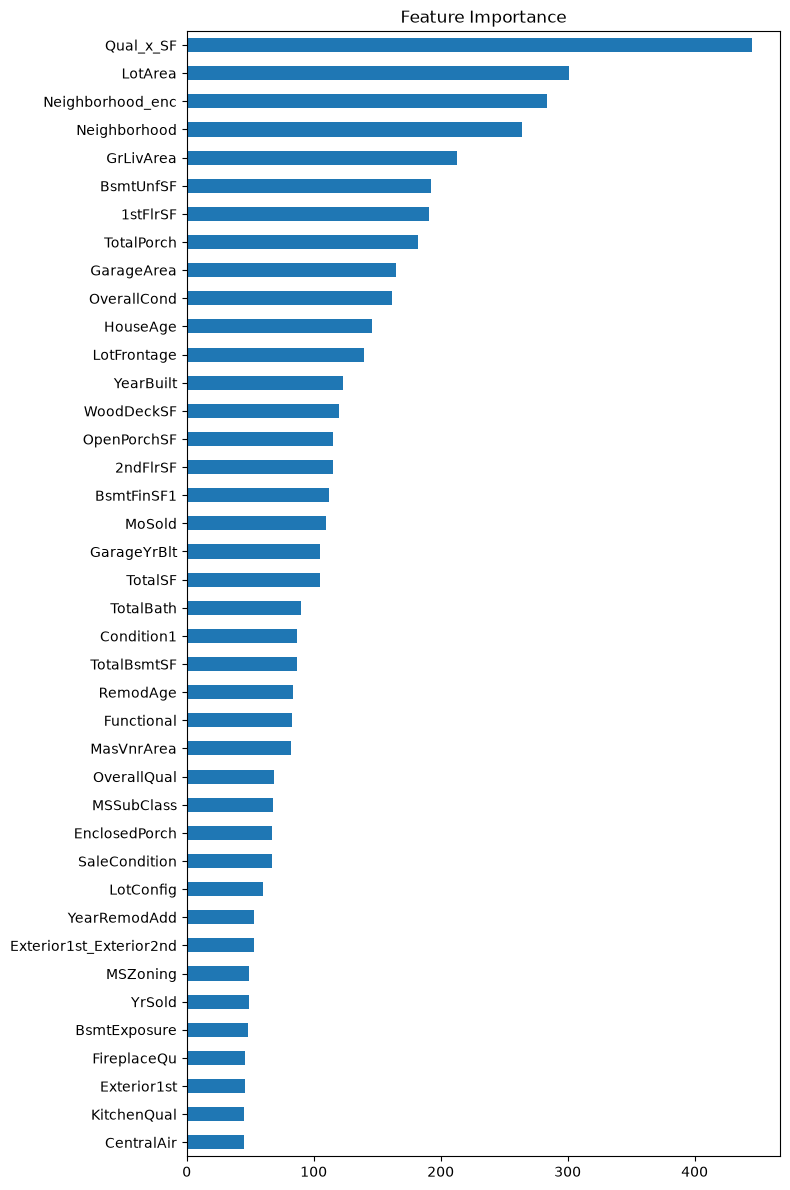

In [ ]:
# 你的最佳参数
best_params = search.best_params_

# ---------- 1) 先看重要性 ----------
model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1, n_jobs=-1)
model.fit(x_train, y_train)

importance = pd.Series(model.feature_importances_, index=x_train.columns).sort_values(ascending=False)
print("特征重要性 Top 20：")
print(importance.head(20))

plt.figure(figsize=(8, 12))
importance.head(40)[::-1].plot(kind='barh')
plt.title('Feature Importance')
plt.tight_layout()
plt.show()

In [91]:
from sklearn.preprocessing import PolynomialFeatures

# 1) 前 10 个重要性特征里，只挑数值型（多项式不能对 category 做）
top10 = importance.index[:10].tolist()
num_feats = [c for c in top10 if pd.api.types.is_numeric_dtype(x_train[c])]
print("用于多项式的数值特征:", num_feats)

# 2) 生成 degree=2 多项式（平方 + 两两交互）
poly = PolynomialFeatures(degree=2, include_bias=False)
poly_arr  = poly.fit_transform(x_train[num_feats])
poly_names = poly.get_feature_names_out(num_feats)

# 3) 只保留"新生成"的列（去掉原始的 num_feats 本身），并清洗列名
new_names = [n for n in poly_names if n not in num_feats]
x_poly = pd.DataFrame(poly_arr, columns=poly_names, index=x_train.index)[new_names].copy()
x_poly.columns = [c.replace(' ', '_x_').replace('^', '_sq') for c in x_poly.columns]
new_names = x_poly.columns.tolist()

print("新增多项式特征数:", len(new_names))
print(new_names)

# 4) 拼回重训，看新特征重要性
x_train2 = pd.concat([x_train, x_poly], axis=1)
model2 = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1, n_jobs=-1,
                           importance_type='gain')   # 用 gain 更公平
model2.fit(x_train2, y_train)

imp2 = pd.Series(model2.feature_importances_, index=x_train2.columns).sort_values(ascending=False)

# 5) 保留挤进总特征前 50 的多项式新特征
top50 = set(imp2.index[:50])
keep_poly = [c for c in new_names if c in top50]
drop_poly = [c for c in new_names if c not in top50]

print(f"\n保留的多项式特征（{len(keep_poly)} 个）:")
print(keep_poly)
print(f"\n删除的多项式特征（{len(drop_poly)} 个）:")
print(drop_poly)

# 6) 最终训练特征 = 原始 + 保留的多项式
final_cols = x_train.columns.tolist() + keep_poly
x_train_final = x_train2[final_cols]

用于多项式的数值特征: ['Qual_x_SF', 'LotArea', 'Neighborhood_enc', 'GrLivArea', 'BsmtUnfSF', '1stFlrSF', 'TotalPorch', 'GarageArea', 'OverallCond']
新增多项式特征数: 45
['Qual_x_SF_sq2', 'Qual_x_SF_x_LotArea', 'Qual_x_SF_x_Neighborhood_enc', 'Qual_x_SF_x_GrLivArea', 'Qual_x_SF_x_BsmtUnfSF', 'Qual_x_SF_x_1stFlrSF', 'Qual_x_SF_x_TotalPorch', 'Qual_x_SF_x_GarageArea', 'Qual_x_SF_x_OverallCond', 'LotArea_sq2', 'LotArea_x_Neighborhood_enc', 'LotArea_x_GrLivArea', 'LotArea_x_BsmtUnfSF', 'LotArea_x_1stFlrSF', 'LotArea_x_TotalPorch', 'LotArea_x_GarageArea', 'LotArea_x_OverallCond', 'Neighborhood_enc_sq2', 'Neighborhood_enc_x_GrLivArea', 'Neighborhood_enc_x_BsmtUnfSF', 'Neighborhood_enc_x_1stFlrSF', 'Neighborhood_enc_x_TotalPorch', 'Neighborhood_enc_x_GarageArea', 'Neighborhood_enc_x_OverallCond', 'GrLivArea_sq2', 'GrLivArea_x_BsmtUnfSF', 'GrLivArea_x_1stFlrSF', 'GrLivArea_x_TotalPorch', 'GrLivArea_x_GarageArea', 'GrLivArea_x_OverallCond', 'BsmtUnfSF_sq2', 'BsmtUnfSF_x_1stFlrSF', 'BsmtUnfSF_x_TotalPorch', 'BsmtU

In [92]:
def cv_rmse(X, y, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = []
    for tr, va in kf.split(X):
        m = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1, n_jobs=-1)
        m.fit(X.iloc[tr], y.iloc[tr])
        pred = m.predict(X.iloc[va])
        scores.append(np.sqrt(mean_squared_error(y.iloc[va], pred)))
    return np.mean(scores), np.std(scores)

# 对比：原始特征 vs 加多项式特征
base_mean, base_std = cv_rmse(x_train, y_train)          # 原始
poly_mean, poly_std = cv_rmse(x_train_final, y_train)    # 加多项式

print(f"原始特征      CV RMSLE: {base_mean:.5f} (±{base_std:.5f})")
print(f"加多项式特征  CV RMSLE: {poly_mean:.5f} (±{poly_std:.5f})")
print(f"\n变化: {poly_mean - base_mean:+.5f}  (负数 = 变好)")


原始特征      CV RMSLE: 0.12723 (±0.01129)
加多项式特征  CV RMSLE: 0.12698 (±0.01576)

变化: -0.00025  (负数 = 变好)


In [93]:
# 1) 测试集用同一个 poly 变换，取同样保留的 24 个特征
test_poly = pd.DataFrame(poly.transform(x_test[num_feats]),
                         columns=poly_names, index=x_test.index)
test_poly.columns = [c.replace(' ', '_x_').replace('^', '_sq') for c in test_poly.columns]
x_test_final = pd.concat([x_test, test_poly[keep_poly]], axis=1)

# 2) 安全校验：train / test 特征列必须完全一致（test 多一个 Id）
assert set(x_train_final.columns) == set(x_test_final.drop(columns=['Id']).columns), \
    "train/test 特征列不一致，检查！"

### 用Z-score检测异常值

In [113]:
# 真实价格（y_train 是 log，用 expm1 还原）
y_price = np.expm1(y_train.values)

# 只扫数值列（跳过 category）
num_cols = x_train_final.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("参与扫描的数值特征:", len(num_cols))

# 逐特征：MAD（修正 Z-score）标记，|M| > 3.5 算异常
flag = pd.DataFrame(index=x_train_final.index)
for c in num_cols:
    s = x_train_final[c]
    med = s.median()
    mad = (s - med).abs().median()
    flag[c] = (0.6745 * (s - med) / mad).abs() > 3.5 if mad > 0 else False

# 每个特征有多少异常
per_feat = flag.sum(axis=0).sort_values(ascending=False)
#print("\n各特征异常数 Top20:\n", per_feat.head(20))

# 每个样本被几个特征标记
n_flag = flag.sum(axis=1)
#print("\n样本被标记次数分布:\n", n_flag.value_counts().sort_index())

# 多特征共识：被 >= 5 个特征同时标记的才看
thr = 10
cand = n_flag[n_flag >= thr].sort_values(ascending=False)
print(f"\n被 >= {thr} 个特征同时标记: {len(cand)} 个")
for i in cand.index:
    feats = flag.columns[flag.loc[i]].tolist()
    print(f"\n行号={i}  价格={y_price[i]:,.0f}  被{len(feats)}个特征标记")
    print("   ", {f: round(float(x_train_final.loc[i, f]), 1) for f in feats})


参与扫描的数值特征: 90

被 >= 10 个特征同时标记: 41 个

行号=1298  价格=160,000  被33个特征标记
    {'LotFrontage': 313.0, 'LotArea': 63887.0, 'BsmtFinSF1': 5644.0, 'TotalBsmtSF': 6110.0, '1stFlrSF': 4692.0, 'GrLivArea': 5642.0, 'TotRmsAbvGrd': 12.0, 'GarageArea': 1418.0, 'OpenPorchSF': 292.0, 'TotalSF': 11752.0, 'Qual_x_SF': 117520.0, 'Qual_x_SF_sq2': 13810950400.0, 'Qual_x_SF_x_LotArea': 7508000240.0, 'Qual_x_SF_x_Neighborhood_enc': 1374020.2, 'Qual_x_SF_x_GrLivArea': 663047840.0, 'Qual_x_SF_x_BsmtUnfSF': 54764320.0, 'Qual_x_SF_x_1stFlrSF': 551403840.0, 'Qual_x_SF_x_GarageArea': 166643360.0, 'Qual_x_SF_x_OverallCond': 587600.0, 'LotArea_x_GrLivArea': 360450454.0, 'LotArea_x_BsmtUnfSF': 29771342.0, 'LotArea_x_1stFlrSF': 299757804.0, 'LotArea_x_TotalPorch': 18655004.0, 'LotArea_x_GarageArea': 90591766.0, 'LotArea_x_OverallCond': 319435.0, 'Neighborhood_enc_x_GrLivArea': 65965.1, 'GrLivArea_x_1stFlrSF': 26472264.0, 'GrLivArea_x_OverallCond': 28210.0, 'BsmtUnfSF_x_1stFlrSF': 2186472.0, 'BsmtUnfSF_x_TotalPorch': 136

这里借助了AI帮我查看这些异常值到底有哪些是真正异常的

In [114]:
# 要删的行号
drop_idx = [1298, 523]

# 删掉指定行，赋给新变量（原 x_train_final / y_train 不动）
x_train_clean = x_train_final.drop(index=drop_idx).copy()
y_train_clean = y_train.drop(index=drop_idx).copy()

print("删除前:", x_train_final.shape, y_train.shape)
print("删除后:", x_train_clean.shape, y_train_clean.shape)

删除前: (1460, 116) (1460,)
删除后: (1458, 116) (1458,)


In [115]:
# 对比：原始特征 vs 加多项式特征
base_mean, base_std = cv_rmse(x_train_final, y_train)           
poly_mean, poly_std = cv_rmse(x_train_clean, y_train_clean)     

print(f"原始特征    CV RMSLE: {base_mean:.5f} (±{base_std:.5f})")
print(f"清洗后特征  CV RMSLE: {poly_mean:.5f} (±{poly_std:.5f})")
print(f"\n变化: {poly_mean - base_mean:+.5f}  (负数 = 变好)")


原始特征    CV RMSLE: 0.12698 (±0.01576)
清洗后特征  CV RMSLE: 0.11655 (±0.00933)

变化: -0.01042  (负数 = 变好)


### 最后采用集成学习，用三个模型+一个元模型训练

In [ ]:
# ============ 参数搜索空间 ============
param_grid = {
    'n_estimators':      [500, 1000, 2000, 3000],
    'learning_rate':     [0.01, 0.03, 0.05, 0.08],
    'num_leaves':        [15, 31, 63, 127],
    'max_depth':         [-1, 3, 5, 7],
    'min_child_samples': [10, 20, 40, 80],     # 小数据集防过拟合的关键参数
    'subsample':         [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 1.0],
    'reg_alpha':         [0, 0.1, 1, 10],
    'reg_lambda':        [0, 0.1, 1, 10],
}
# ============ 模型 + 随机搜索 ============
lgb_model = lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_grid,
    n_iter=50,                                  # 随机抽 50 组组合
    scoring='neg_root_mean_squared_error',      # log 尺度 → 就是 RMSLE
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(x_train_clean, y_train_clean)
best_params = search.best_params_
print("========== 搜索完成 ==========")
print("最佳参数:", search.best_params_)
print("CV RMSLE:", -search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
========== 搜索完成 ==========
最佳参数: {'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0, 'num_leaves': 127, 'n_estimators': 1000, 'min_child_samples': 20, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
CV RMSLE: 0.11655491075529265


In [119]:
from xgboost import XGBRegressor

xgb_grid = {
    'n_estimators':      [500, 1000, 2000],
    'learning_rate':     [0.01, 0.03, 0.05, 0.08],
    'max_depth':         [3, 4, 5, 6, 8],
    'min_child_weight':  [1, 3, 5, 10],
    'subsample':         [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 1.0],
    'reg_alpha':         [0, 0.1, 1, 10],
    'reg_lambda':        [1, 3, 10],
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(enable_categorical=True, tree_method='hist',
                 random_state=42, n_jobs=-1, verbosity=0),
    param_distributions=xgb_grid,
    n_iter=40,
    scoring='neg_root_mean_squared_error',
    cv=KFold(5, shuffle=True, random_state=42),
    random_state=42, n_jobs=1, verbose=1,
)
xgb_search.fit(x_train_clean, y_train_clean)

best_params_2 = xgb_search.best_params_
print("XGB best:", best_params_2)
print("XGB CV RMSLE:", -xgb_search.best_score_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
XGB best: {'subsample': 0.7, 'reg_lambda': 3, 'reg_alpha': 0, 'n_estimators': 2000, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
XGB CV RMSLE: 0.113861013974957


In [120]:
from sklearn.ensemble import HistGradientBoostingRegressor

hist_grid = {
    'max_iter':          [500, 1000, 2000],
    'learning_rate':     [0.01, 0.03, 0.05, 0.08],
    'max_depth':         [None, 3, 5, 8],
    'max_leaf_nodes':    [15, 31, 63],
    'min_samples_leaf':  [10, 20, 40],
    'l2_regularization': [0, 0.1, 1, 10],
}

hist_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(categorical_features='from_dtype',
                                  random_state=42),
    param_distributions=hist_grid,
    n_iter=40,
    scoring='neg_root_mean_squared_error',
    cv=KFold(5, shuffle=True, random_state=42),
    random_state=42, n_jobs=1, verbose=1,
)
hist_search.fit(x_train_clean, y_train_clean)

best_params_3 = hist_search.best_params_
print("Hist best:", best_params_3)
print("Hist CV RMSLE:", -hist_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Hist best: {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 2000, 'max_depth': 3, 'learning_rate': 0.01, 'l2_regularization': 0.1}
Hist CV RMSLE: 0.11715286195243627


In [122]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

base_models = [
    ('lgb',  lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1, **best_params)),
    ('xgb',  XGBRegressor(enable_categorical=True, tree_method='hist',
                          random_state=42, n_jobs=-1, verbosity=0, **best_params_2)),
    ('hist', HistGradientBoostingRegressor(categorical_features='from_dtype',
                                           random_state=42, **best_params_3)),
]

stack = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(5, shuffle=True, random_state=42),
    n_jobs=1,
)
stack.fit(x_train_clean, y_train_clean);
# # 预测（去掉 Id）
# pred = np.expm1(stack.predict(x_test_final.drop(columns=['Id'])))

# pd.DataFrame({'Id': x_test_final['Id'], 'SalePrice': pred}).to_csv(
#     'submission_stack.csv', index=False)
# print("已保存 submission_stack.csv，行数:", len(pred))


In [123]:
from sklearn.model_selection import cross_val_score
score = cross_val_score(stack, x_train_clean, y_train_clean, 
                        cv=KFold(5,shuffle=True,random_state=42), 
                        scoring='neg_root_mean_squared_error')
print(score.mean())

-0.11355693478297257


### 输出结果

In [ ]:
# 预测（去掉 Id）
pred = np.expm1(stack.predict(x_test_final.drop(columns=['Id'])))

pd.DataFrame({'Id': x_test_final['Id'], 'SalePrice': pred}).to_csv(
    'submission_stack.csv', index=False)
print("已保存 submission_stack.csv，行数:", len(pred))

已保存 submission_stack.csv，行数: 1459
